## Лабораторная работа №1 | Вариант 5

Выполнил: Колосов Егор Евгеньевич М8О-312БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
matrix = np.eye(3, dtype=int)
print(matrix)

[[1 0 0]
 [0 1 0]
 [0 0 1]]


2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba = np.dtype([('r', 'u1'), ('g', 'u1'), ('b', 'u1'), ('a', 'u1')])
pixel = np.array([(255, 128, 0, 255)], dtype=rgba)
print(pixel)
print(rgba.itemsize)

[(255, 128, 0, 255)]
4


3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    with np.errstate(all='ignore'):
        print(np.array([1.0, 0.0]) / 0)

[inf nan]


4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
arr = np.random.random(10)
print(arr)
arr.sort()
print(arr)

[0.94915681 0.83058743 0.45672525 0.44507586 0.67586578 0.64227478
 0.4229132  0.68083106 0.67918946 0.89877928]
[0.4229132  0.44507586 0.45672525 0.64227478 0.67586578 0.67918946
 0.68083106 0.83058743 0.89877928 0.94915681]


5. Создайте read-only массив(неизменяемый)

In [6]:
arr = np.arange(5)
arr.setflags(write=False)
print(arr)
print(arr.flags.writeable)

[0 1 2 3 4]
False


6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
coords = np.random.uniform(-1, 1, (10, 2))
r = np.hypot(coords[:, 0], coords[:, 1])
angle = np.arctan2(coords[:, 1], coords[:, 0])
polar = np.column_stack((r, angle))
print(polar)

[[ 1.1228084  -0.73318306]
 [ 0.47452785  2.52909524]
 [ 0.78708794 -1.34803033]
 [ 0.48482714 -2.47296167]
 [ 0.73098892  0.05773077]
 [ 0.99751751 -0.41092993]
 [ 0.76724175 -1.01885311]
 [ 0.78970762 -0.88007053]
 [ 0.98525904 -1.65865519]
 [ 0.64455141  0.63579916]]


7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
grid = np.zeros((5, 5), dtype=[('x', float), ('y', float)])
values = np.linspace(0, 1, 5)
grid['x'], grid['y'] = np.meshgrid(values, values)
print(grid)

[[(0.  , 0.  ) (0.25, 0.  ) (0.5 , 0.  ) (0.75, 0.  ) (1.  , 0.  )]
 [(0.  , 0.25) (0.25, 0.25) (0.5 , 0.25) (0.75, 0.25) (1.  , 0.25)]
 [(0.  , 0.5 ) (0.25, 0.5 ) (0.5 , 0.5 ) (0.75, 0.5 ) (1.  , 0.5 )]
 [(0.  , 0.75) (0.25, 0.75) (0.5 , 0.75) (0.75, 0.75) (1.  , 0.75)]
 [(0.  , 1.  ) (0.25, 1.  ) (0.5 , 1.  ) (0.75, 1.  ) (1.  , 1.  )]]


8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = np.random.normal(size=(5))
y = np.random.normal(size=(5))

c = 1 / (x[:, None] - y[None, :])
print(c)

[[-0.2979123  -0.99384387 -9.71757362 -0.69676773 -0.46520297]
 [-0.98188678  0.75072207  0.44735948  1.10736249  5.30093961]
 [-1.91709074  0.54678437  0.36601045  0.71435189  1.45885424]
 [-0.83941311  0.86267156  0.48485374  1.36951503 63.35278383]
 [-0.48224078  3.61212529  0.84736194 -6.57207709 -1.1539885 ]]


9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
arr = np.array([1.8, -2.9, 3.0, 0.4], dtype=np.float32)
arr_int = arr.view(np.int32)
arr_int[:] = arr.astype(np.int32)
arr = arr_int
print(arr, arr.dtype)

[ 1 -2  3  0] int32


10. Как случайно заменить p элементов в 2D массиве?

In [11]:
arr = np.arange(20).reshape(4, 5)
p = 5
positions = np.random.choice(arr.size, p, replace=False)
arr.flat[positions] = -1
print(arr)

[[ 0  1  2  3 -1]
 [ 5  6  7 -1 -1]
 [10 11 12 13 14]
 [-1 16 17 18 -1]]


### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv('data.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


В заданиях по возрасту пропуски не учитываются, в остальных используются все строки

1. Узнайте сколько было на борту человек

In [14]:
print(len(df))

891


2. Какой медианный и средний возраста пассажиров

In [15]:
print('Медианный возраст:', df['Age'].median())
print('Средний возраст:', round(df['Age'].mean(), 2))

Медианный возраст: 28.0
Средний возраст: 29.7


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
children = df[df['Age'] < 16]
adults = df[df['Age'] >= 16]
print('Дети до 16 лет:', round(children['Survived'].mean() * 100, 2), '%')
print('Взрослые от 16 лет:', round(adults['Survived'].mean() * 100, 2), '%')

Дети до 16 лет: 59.04 %
Взрослые от 16 лет: 38.19 %


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
women = df[(df['Sex'] == 'female') & (df['Age'] >= 16)]
men = df[(df['Sex'] == 'male') & (df['Age'] >= 16)]
survival = pd.Series({
    'Мужчины 16+': men['Survived'].mean() * 100,
    'Женщины 16+': women['Survived'].mean() * 100,
    'Дети до 16 лет': children['Survived'].mean() * 100
})
print(survival.round(2))

Мужчины 16+       17.43
Женщины 16+       77.52
Дети до 16 лет    59.04
dtype: float64


Пояснение к заданию 4

Женщины и дети выживали чаще взрослых мужчин, но порядок посадки в шлюпки по этим данным определить нельзя

5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print((df.groupby('Pclass')['Survived'].mean() * 100).round(2))

Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


В 1-м классе выживаемость выше всего, в 3-м — ниже всего

6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
dead = df[df['Survived'] == 0]
print(dead.groupby('Sex')['Age'].mean().round(2))

Sex
female    25.05
male      31.62
Name: Age, dtype: float64


7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
has_relatives = df['SibSp'] + df['Parch'] > 0
print('С родственниками:', round(df.loc[has_relatives, 'Survived'].mean() * 100, 2), '%')
print('Одиночки:', round(df.loc[~has_relatives, 'Survived'].mean() * 100, 2), '%')

С родственниками: 50.56 %
Одиночки: 30.35 %


У пассажиров с родственниками доля выживших выше: 50,56% против 30,35% у одиночек

8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(df.groupby('Survived')['Fare'].mean().round(2))

Survived
0    22.12
1    48.40
Name: Fare, dtype: float64


Средняя стоимость билета у выживших выше: 48,40 против 22,12 у погибших

9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
ages = df[(df['Survived'] == 1) & (df['Pclass'] == 2)]['Age']
print('Минимальный возраст:', ages.min())
print('Максимальный возраст:', ages.max())

Минимальный возраст: 0.67
Максимальный возраст: 62.0


10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
men = df[(df['Sex'] == 'male') & (df['Age'] >= 18)]
young = men[men['Age'] < 30]
older = men[men['Age'] >= 30]
print('Мужчины от 18 до 29 лет:', round(young['Survived'].mean() * 100, 2), '%')
print('Мужчины от 30 лет:', round(older['Survived'].mean() * 100, 2), '%')

Мужчины от 18 до 29 лет: 15.64 %
Мужчины от 30 лет: 19.44 %


Пояснение к заданию 10

За границу взят возраст 30 лет, так как в условии она не указана
При таком разделении гипотеза не подтверждается: выжили 15,64% молодых мужчин и 19,44% более взрослых

### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

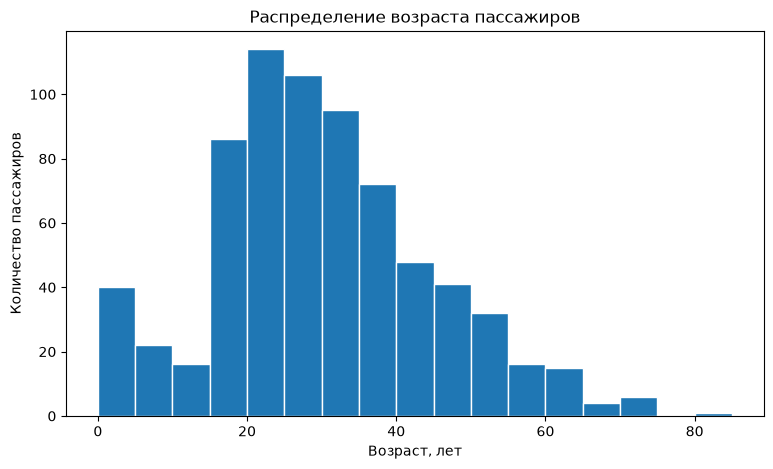

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df['Age'].dropna(), bins=np.arange(0, 86, 5), edgecolor='white')
plt.title('Распределение возраста пассажиров')
plt.xlabel('Возраст, лет')
plt.ylabel('Количество пассажиров')
plt.show()

Среди пассажиров с известным возрастом больше всего людей от 20 до 40 лет

2. Постройте гистограммы распределения цен для пассажиров разных классов

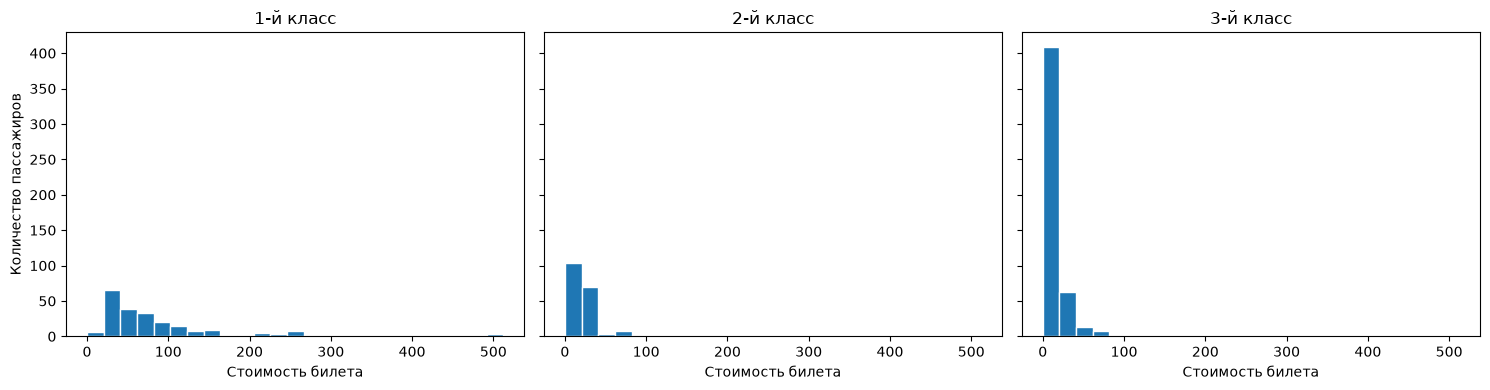

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True, sharey=True)
bins = np.linspace(0, df['Fare'].max(), 26)
for pclass, ax in zip([1, 2, 3], axes):
    ax.hist(df[df['Pclass'] == pclass]['Fare'], bins=bins, edgecolor='white')
    ax.set_title(f'{pclass}-й класс')
    ax.set_xlabel('Стоимость билета')
axes[0].set_ylabel('Количество пассажиров')
plt.tight_layout()
plt.show()

В 1-м классе цены сильнее различаются и встречаются самые дорогие билеты

3. Постройте зависимость цены от возраста пассажира

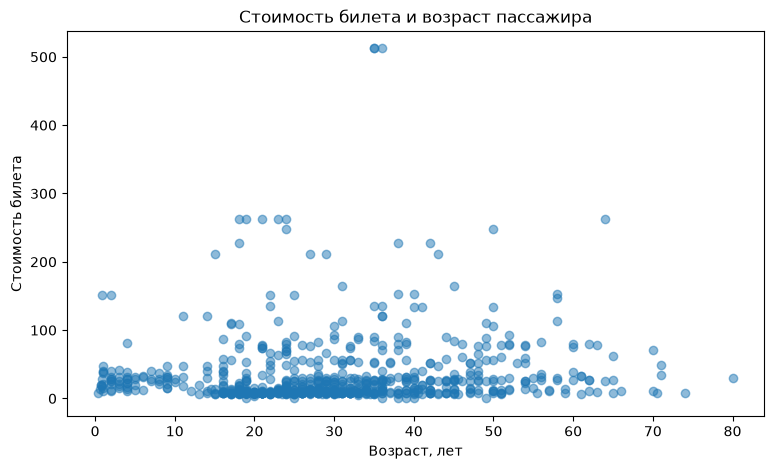

In [26]:
data = df.dropna(subset=['Age', 'Fare'])
plt.figure(figsize=(9, 5))
plt.scatter(data['Age'], data['Fare'], alpha=0.5)
plt.title('Стоимость билета и возраст пассажира')
plt.xlabel('Возраст, лет')
plt.ylabel('Стоимость билета')
plt.show()

Сильной зависимости цены от возраста не видно, у пассажиров одного возраста цены могут заметно различаться

4. Постройте box plot отображающий распределение цен на билеты в разных классах

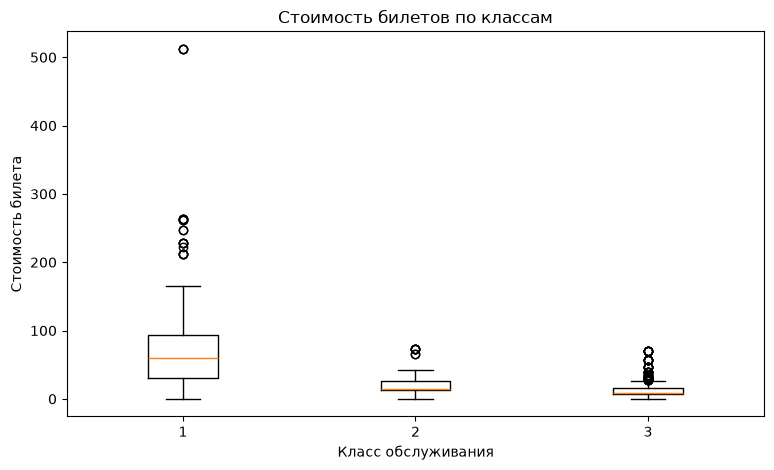

In [27]:
fares = [df[df['Pclass'] == pclass]['Fare'].dropna() for pclass in [1, 2, 3]]
plt.figure(figsize=(9, 5))
plt.boxplot(fares)
plt.title('Стоимость билетов по классам')
plt.xlabel('Класс обслуживания')
plt.ylabel('Стоимость билета')
plt.show()

В 1-м классе выше медианная цена и больше разброс, в 3-м классе билеты в основном дешевле

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

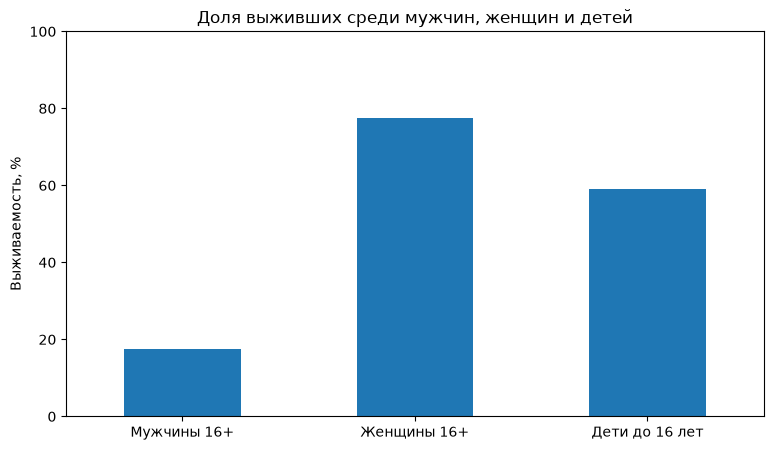

In [28]:
plt.figure(figsize=(9, 5))
survival.plot(kind='bar', rot=0)
plt.title('Доля выживших среди мужчин, женщин и детей')
plt.ylabel('Выживаемость, %')
plt.ylim(0, 100)
plt.show()

Среди взрослых женщин доля выживших самая высокая, у детей ниже, у взрослых мужчин самая низкая

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

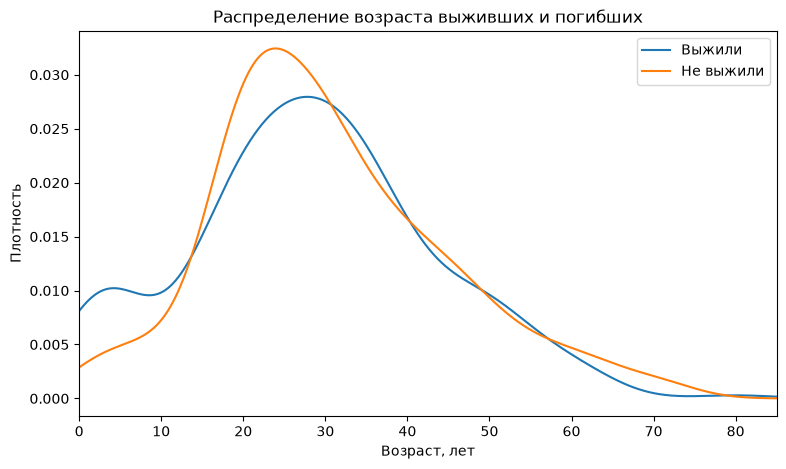

In [29]:
fig, ax = plt.subplots(figsize=(9, 5))
df[df['Survived'] == 1]['Age'].dropna().plot.kde(ax=ax, label='Выжили')
df[df['Survived'] == 0]['Age'].dropna().plot.kde(ax=ax, label='Не выжили')
ax.set_xlim(0, 85)
ax.set_title('Распределение возраста выживших и погибших')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Плотность')
ax.legend()
plt.show()

Вывод к заданию 6

В обеих группах много молодых взрослых, но среди выживших заметнее доля маленьких детей
Здесь сравниваются плотности распределения возраста, а не количество пассажиров

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл

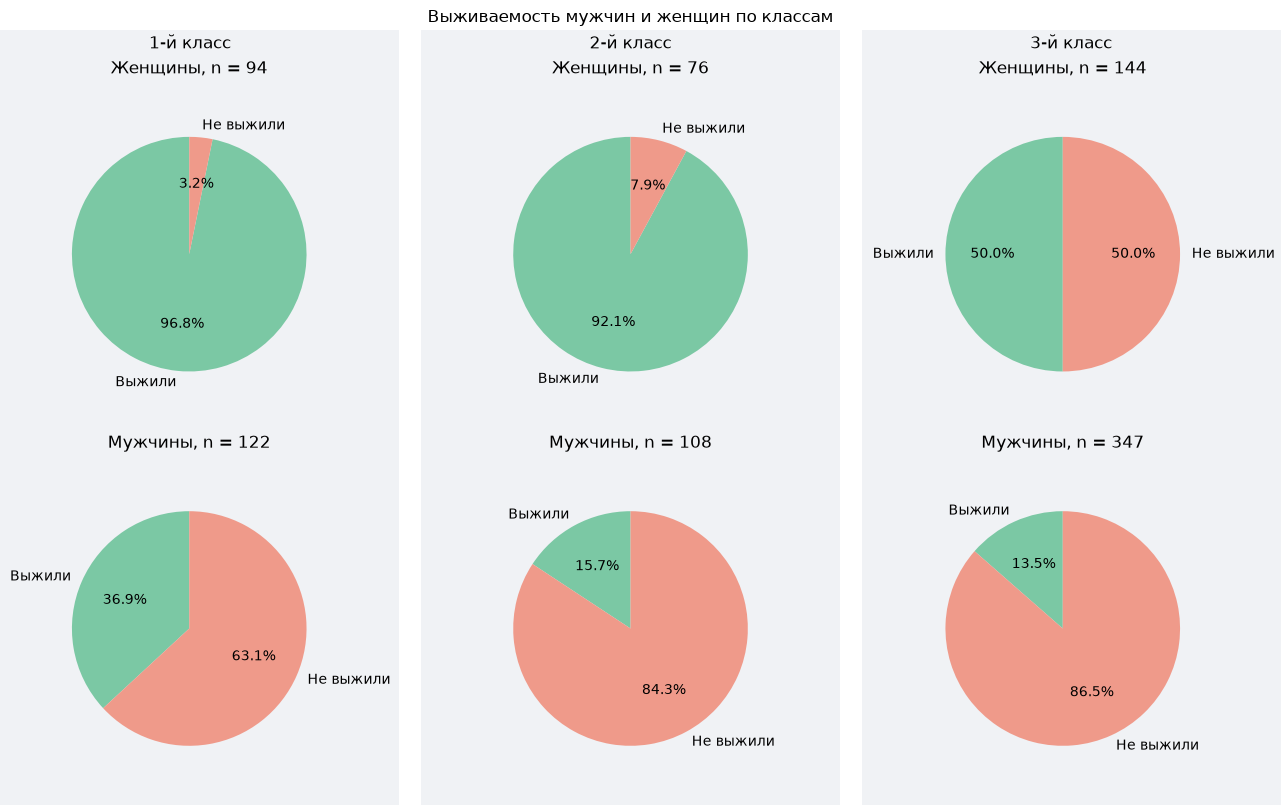

In [30]:
fig = plt.figure(figsize=(13, 8), layout='constrained')
fig.suptitle('Выживаемость мужчин и женщин по классам')
subfigs = fig.subfigures(1, 3, wspace=0.05)

for pclass, subfig in zip([1, 2, 3], subfigs):
    subfig.set_facecolor('#f0f2f5')
    subfig.suptitle(f'{pclass}-й класс')
    axes = subfig.subplots(2, 1)
    for ax, sex, label in zip(axes, ['female', 'male'], ['Женщины', 'Мужчины']):
        group = df[(df['Pclass'] == pclass) & (df['Sex'] == sex)]
        counts = group['Survived'].value_counts().reindex([1, 0], fill_value=0)
        ax.pie(counts, labels=['Выжили', 'Не выжили'], autopct='%1.1f%%',
               startangle=90, radius=0.85, colors=['#7bc8a4', '#ef9a8a'])
        ax.set_title(f'{label}, n = {len(group)}')

plt.show()

В каждом классе женщины выживали чаще мужчин, здесь группы по полу включают пассажиров всех возрастов